In [1]:
import importlib
import functions_grid_search
importlib.reload(functions_grid_search)

from functions_grid_search import choose_variables_train_data, choose_variables_lags, lags_restrict, scaling, fit_model, apply_models, print_results, crosscorr_table, _evaluate


import os
import time
import numpy as np
import pandas as pd
from itertools import product
from sklearn.model_selection import TimeSeriesSplit

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import r2_score, mean_squared_error

# Read data
df = pd.read_excel("chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")

# Order dates
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Com Funções

## Escolhas manuais (divide em 3 passos)

In [2]:
'''
Para test_year=2023 | use_log=True | outlier_mode='Median' | drop_mode='manual' | 'Ridge' | scaler_mode='Robust' | lag_selection='manual'
'''

# passo 1
prep = choose_variables_train_data(df, test_year=2023, use_log=True, outlier_mode='Median')
prep['corr']                                   # read it

,chlorophyll_a_mg_m3,sst_c,par_umol_m2_s,nitrate_umol_l,wind_speed_m_s,upwelling_index,mixed_layer_depth_m,salinity_psu,current_speed_m_s,river_discharge_index,cloud_fraction,surface_pressure_hpa,turbidity_ntu
chlorophyll_a_mg_m3,1.000000,-0.635319,-0.609852,0.623766,0.238613,0.430971,0.491356,-0.130151,0.124290,0.490208,0.445524,0.059515,0.322053
sst_c,-0.635319,1.000000,0.950503,-0.874066,-0.166880,-0.511277,-0.672489,0.077671,-0.015982,-0.694123,-0.691669,-0.064630,-0.476499
par_umol_m2_s,-0.609852,0.950503,1.000000,-0.827825,-0.176419,-0.481431,-0.784971,0.073797,-0.014416,-0.601684,-0.675512,-0.098089,-0.412906
nitrate_umol_l,0.623766,-0.874066,-0.827825,1.000000,0.524802,0.810436,0.721710,-0.226784,0.369622,0.715093,0.594513,0.061532,0.494465
wind_speed_m_s,0.238613,-0.166880,-0.176419,0.524802,1.000000,0.854672,0.504028,-0.004068,0.834793,0.091937,0.118036,0.008527,0.084977
upwelling_index,0.430971,-0.511277,-0.481431,0.810436,0.854672,1.000000,0.624065,-0.035228,0.721678,0.349402,0.339143,0.009422,0.263064
mixed_layer_depth_m,0.491356,-0.672489,-0.784971,0.721710,0.504028,0.624065,1.000000,-0.007637,0.328417,0.330350,0.561683,0.119529,0.236347
salinity_psu,-0.130151,0.077671,0.073797,-0.226784,-0.004068,-0.035228,-0.007637,1.000000,-0.020026,-0.614602,0.133584,-0.103164,-0.358006
current_speed_m_s,0.124290,-0.015982,-0.014416,0.369622,0.834793,0.721678,0.328417,-0.020026,1.000000,0.015423,-0.006501,0.005135,0.021234
river_discharge_index,0.490208,-0.694123,-0.601684,0.715093,0.091937,0.349402,0.330350,-0.614602,0.015423,1.000000,0.508989,0.068470,0.656340


In [3]:
# passo 2
data = choose_variables_lags(prep, drop_mode='manual', drop_vars=['surface_pressure_hpa', 'par_umol_m2_s', 'wind_speed_m_s'])
data['crosscorr']                              # read it
print(data['crosscorr'])

crosscorr_table(data)

chlorophyll_a_mg_m3__lag_1    0.839722
nitrate_umol_l__lag_3         0.792237
nitrate_umol_l__lag_2         0.772557
upwelling_index__lag_3        0.727878
nitrate_umol_l__lag_4         0.726442
                                ...   
salinity_psu__lag_6           0.125887
current_speed_m_s__lag_0      0.124097
salinity_psu__lag_7           0.111687
current_speed_m_s__lag_6      0.106675
current_speed_m_s__lag_7      0.060462
Length: 107, dtype: float64


lag,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
variable,,,,,,,,,,,,,,,
chlorophyll_a_mg_m3,NaN,0.840,0.688,0.575,0.514,0.490,0.495,0.509,0.507,0.492,0.460,0.428,0.419,0.413,0.414
cloud_fraction,0.452,0.445,0.435,0.436,0.447,0.461,0.462,0.455,NaN,NaN,NaN,NaN,NaN,NaN,NaN
current_speed_m_s,0.124,0.261,0.403,0.414,0.303,0.177,0.107,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mixed_layer_depth_m,0.500,0.542,0.594,0.592,0.537,0.483,0.450,0.425,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nitrate_umol_l,0.631,0.695,0.773,0.792,0.726,0.653,0.615,0.590,0.581,0.588,0.590,0.586,0.573,0.555,0.549
river_discharge_index,0.498,0.503,0.511,0.522,0.524,0.521,0.518,0.508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salinity_psu,0.133,0.139,0.152,0.162,0.157,0.137,0.126,0.112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sst_c,0.644,0.645,0.650,0.651,0.647,0.640,0.639,0.638,0.639,0.639,0.639,0.637,0.632,0.628,0.624
turbidity_ntu,0.329,0.334,0.348,0.363,0.363,0.359,0.353,0.339,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# passo 3
res = apply_models(data, 'Ridge', scaler_mode='Robust',
                   lag_selection='manual',
                   selected_lags=['chlorophyll_a_mg_m3__lag_1', 'nitrate_umol_l__lag_2', 'nitrate_umol_l__lag_3', 'nitrate_umol_l__lag_4', 
                                  'upwelling_index__lag_2', 'upwelling_index__lag_3'])
print_results(res)

''' fazer com os melhores 20
selected = data['crosscorr'].head(20).index.tolist()    # 20 strongest lag columns
res = apply_models(data, 'Ridge', scaler_mode='Robust',
                   lag_selection='manual', selected_lags=selected)
print_results(res)
'''

Model: Ridge | log: True | outliers: Median | features: 125 -> 8
Dropped variables (auto): ['par_umol_m2_s']
Lag selection: manual
Alpha: 0.01
        before     after
R2    0.844544  0.833197
MAE   0.160679  0.166846
RMSE  0.218677  0.226518
MSE   0.047820  0.051310
MAPE  0.095483  0.099456
--- RobustScaler parameters ---
                              median       IQR
annual_sin                 -0.006451  1.425568
annual_cos                 -0.011826  1.410367
chlorophyll_a_mg_m3__lag_1  0.474863  0.453422
nitrate_umol_l__lag_2       4.336430  2.318715
nitrate_umol_l__lag_3       4.336430  2.318715
nitrate_umol_l__lag_4       4.336430  2.318715
upwelling_index__lag_2     -0.043902  1.431792
upwelling_index__lag_3     -0.043902  1.430755


" fazer com os melhores 20\nselected = data['crosscorr'].head(20).index.tolist()    # 20 strongest lag columns\nres = apply_models(data, 'Ridge', scaler_mode='Robust',\n                   lag_selection='manual', selected_lags=selected)\nprint_results(res)\n"

## Escolhas automaticas (faz os 3 passos de seguida)

In [ ]:
'''
Para test_year=2022 | use_log=True | Median | drop_mode='auto' | high_corr=0.9 | low_target_corr=0.05 | 'Ridge' | scaler_mode='Robust' | lag_selection='auto' |  corr_threshold=0.2
'''
prep = choose_variables_train_data(df, test_year=2022, use_log=True, outlier_mode='Median') # igual ao outro passo 1

data = choose_variables_lags(prep, drop_mode='auto', high_corr=0.9, low_target_corr=0.05)
res = apply_models(data, 'Ridge', scaler_mode='Robust',
                   lag_selection='auto', corr_threshold=0.2)

print_results(res)

Model: Ridge | log: True | outliers: Median | features: 125 -> 103
Dropped variables (auto): ['par_umol_m2_s']
Lag selection: auto
Alpha (cross-validated): 16.1443
        before     after
R2    0.844273  0.842557
MAE   0.160743  0.160854
RMSE  0.218868  0.220070
MSE   0.047903  0.048431
MAPE  0.095520  0.095565
--- RobustScaler parameters ---
                              median       IQR
annual_sin                 -0.006451  1.425568
annual_cos                 -0.011826  1.410367
chlorophyll_a_mg_m3__lag_1  0.474863  0.453422
nitrate_umol_l__lag_3       4.336430  2.318715
nitrate_umol_l__lag_2       4.336430  2.318715
...                              ...       ...
upwelling_index__lag_14    -0.045701  1.425356
current_speed_m_s__lag_4    0.305223  0.095675
wind_speed_m_s__lag_5       5.932520  1.827976
current_speed_m_s__lag_1    0.305402  0.095885
wind_speed_m_s__lag_0       5.937949  1.831584

[103 rows x 2 columns]


In [4]:
'''
Para test_year=2022 | use_log=True | 'Neighbours' | drop_mode='auto' | high_corr=0.9 | low_target_corr=0.05 | 'Lasso' | scaler_mode='Standard' | lag_selection='auto' |  corr_threshold=0.2
'''
prep = choose_variables_train_data(df, test_year=2022, use_log=True, outlier_mode='Neighbours')

data = choose_variables_lags(prep, drop_mode='auto', high_corr=0.9, low_target_corr=0.05)
res = apply_models(data, 'Lasso', scaler_mode='Standard',
                   lag_selection='auto', corr_threshold=0.2)

print_results(res)

Model: Lasso | log: True | outliers: Neighbours | features: 125 -> 103
Dropped variables (auto): ['par_umol_m2_s']
Lag selection: auto
Alpha: 0.00111384
        before     after
R2    0.848546  0.849003
MAE   0.157185  0.156637
RMSE  0.215845  0.215518
MSE   0.046589  0.046448
MAPE  0.093249  0.092961
Lasso kept 42 of 103 features
--- StandardScaler parameters ---
                                mean       std
annual_sin                 -0.000701  0.708933
annual_cos                 -0.005348  0.705255
chlorophyll_a_mg_m3__lag_1  0.497856  0.322416
nitrate_umol_l__lag_3       4.374492  1.440326
nitrate_umol_l__lag_2       4.374771  1.440717
...                              ...       ...
upwelling_index__lag_14    -0.050445  1.025818
current_speed_m_s__lag_4    0.306421  0.073419
wind_speed_m_s__lag_5       5.947963  1.337622
current_speed_m_s__lag_1    0.306686  0.073646
wind_speed_m_s__lag_0       5.953756  1.343573

[103 rows x 2 columns]


# Grid Search

## Grid Search no Ridge e Lasso - 2023

In [ ]:
# Parametros para grid search 2023
TEST_YEAR = 2023                                       # change only this
VAL_YEARS = list(range(TEST_YEAR - 4, TEST_YEAR))      # 4 validation years

scalers = ['Standard', 'MinMax', 'Robust']
models  = ['Ridge', 'Lasso']
alphas  = {'Ridge': np.logspace(-2, 6, 50), 'Lasso': np.logspace(-5, 1, 50)}

grid_data = {
    'use_log':         [False, True],
    'outlier_mode':    [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
    'high_corr':       [None, 0.8, 0.9, 0.95],
    'low_target_corr': [None, 0.03, 0.05, 0.1],
    'corr_threshold':  [None, 0.1, 0.2, 0.3],
}

os.makedirs('results', exist_ok=True)

In [ ]:
# grid search com GridSearchCV a otimizar nos validate years e a guardar em f'results/grid_gs_test2023.csv'

# the sklearn part: scaler + model + alpha (same alphas as version A)
pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge())])
scaler_options = [StandardScaler(), MinMaxScaler(), RobustScaler()]
param_grid = [
    {'scaler': scaler_options, 'model': [Ridge()], 'model__alpha': alphas['Ridge']},
    {'scaler': scaler_options, 'model': [Lasso(max_iter=20000, random_state=42)],
     'model__alpha': alphas['Lasso']},
]

def make_scorers(use_log):
    """R2 and -RMSE in ORIGINAL units (the log is undone for both prediction and target)."""
    def prep(est, X, y):
        y_pred = est.predict(X)
        return (np.exp(y), np.exp(y_pred)) if use_log else (y, y_pred)
    def r2(est, X, y):
        return r2_score(*prep(est, X, y))
    def neg_rmse(est, X, y):
        return -np.sqrt(mean_squared_error(*prep(est, X, y)))
    return {'r2': r2, 'neg_rmse': neg_rmse}

t_start = time.time()
rows = []
for use_log, outlier_mode in product(grid_data['use_log'], grid_data['outlier_mode']):
    print(f"log={use_log} | outliers={outlier_mode} | "
          f"{(time.time() - t_start) / 60:.1f} min elapsed | {len(rows)} rows")
    preps = {Y: choose_variables_train_data(df, Y, use_log, outlier_mode) for Y in VAL_YEARS}
    seen = set()

    for high_corr, low_corr in product(grid_data['high_corr'], grid_data['low_target_corr']):
        try:
            datas = {Y: choose_variables_lags(preps[Y], drop_mode='auto',
                                              high_corr=high_corr, low_target_corr=low_corr)
                     for Y in VAL_YEARS}
        except Exception as e:
            rows.append({'log': use_log, 'outliers': outlier_mode, 'high_corr': high_corr,
                         'low_corr': low_corr, 'error': str(e)})
            continue

        for thr in grid_data['corr_threshold']:
            cols = {}
            for Y, d in datas.items():
                cols[Y] = list(d['X_train'].columns)
                if thr is not None:
                    cc = d['crosscorr']
                    cols[Y] = list(lags_restrict(d['X_train'], cc[cc >= thr].index.tolist()).columns)

            key = tuple(tuple(c) for c in cols.values())
            if key in seen:
                continue
            seen.add(key)

            base = {'log': use_log, 'outliers': outlier_mode, 'high_corr': high_corr,
                    'low_corr': low_corr, 'corr_threshold': thr,
                    'n_features': len(cols[VAL_YEARS[-1]])}
            try:
                r2_by_year, rmse_by_year = {}, {}
                for Y, d in datas.items():
                    # train rows + validation rows together, with ONE split between them:
                    # the pipeline fits the scaler and the model on the train part only
                    X_all = pd.concat([d['X_train'][cols[Y]], d['X_test'][cols[Y]]])
                    y_all = pd.concat([d['y_train'], d['y_test']])
                    n_train = len(d['X_train'])
                    one_split = [(np.arange(n_train), np.arange(n_train, len(X_all)))]

                    g = GridSearchCV(pipe, param_grid, scoring=make_scorers(use_log),
                                     cv=one_split, refit=False, n_jobs=-1)
                    g.fit(X_all, y_all)
                    r2_by_year[Y] = g.cv_results_['mean_test_r2']
                    rmse_by_year[Y] = -g.cv_results_['mean_test_neg_rmse']

                params = g.cv_results_['params']             # same candidate order every year
                r2_mat = np.vstack([r2_by_year[Y] for Y in VAL_YEARS])      # years x candidates
                rmse_mat = np.vstack([rmse_by_year[Y] for Y in VAL_YEARS])
                mean_r2 = r2_mat.mean(axis=0)

                # best alpha for each scaler/model pair -> one row each
                names = [(type(p['scaler']).__name__.replace('Scaler', ''),
                          type(p['model']).__name__) for p in params]
                for scaler_name, model_name in sorted(set(names)):
                    idx = [i for i, nm in enumerate(names) if nm == (scaler_name, model_name)]
                    b = idx[int(np.argmax(mean_r2[idx]))]
                    rows.append({**base, 'scaler': scaler_name, 'model': model_name,
                                 'alpha': params[b]['model__alpha'],
                                 'R2_mean': mean_r2[b], 'R2_min': r2_mat[:, b].min(),
                                 'RMSE_mean': rmse_mat[:, b].mean(),
                                 **{f'R2_{Y}': r2_mat[i, b] for i, Y in enumerate(VAL_YEARS)}})
            except Exception as e:
                rows.append({**base, 'error': str(e)})

results_gs = pd.DataFrame(rows)
if 'error' not in results_gs.columns:
    results_gs['error'] = None
if 'R2_mean' not in results_gs.columns:
    print(results_gs['error'].value_counts().head())
    raise RuntimeError("Every combination failed, see the errors above.")
results_gs = results_gs.sort_values('R2_mean', ascending=False, na_position='last').reset_index(drop=True)
results_gs.to_csv(f'results/grid_gs_test{TEST_YEAR}.csv', index=False)
print(f"done in {(time.time() - t_start) / 60:.1f} min")
results_gs.head(10)

log=False | outliers=None | 0.0 min elapsed | 0 rows
log=False | outliers=Neighbours | 3.0 min elapsed | 126 rows
log=False | outliers=Mean | 6.3 min elapsed | 270 rows
log=False | outliers=Median | 9.6 min elapsed | 414 rows
log=False | outliers=Mode | 13.3 min elapsed | 558 rows
log=False | outliers=SameDay | 17.4 min elapsed | 738 rows
log=True | outliers=None | 20.7 min elapsed | 882 rows
log=True | outliers=Neighbours | 23.6 min elapsed | 1026 rows
log=True | outliers=Mean | 26.4 min elapsed | 1170 rows
log=True | outliers=Median | 29.5 min elapsed | 1314 rows
log=True | outliers=Mode | 32.5 min elapsed | 1458 rows
log=True | outliers=SameDay | 35.5 min elapsed | 1602 rows
done in 39.8 min


,log,outliers,high_corr,low_corr,corr_threshold,n_features,scaler,model,alpha,R2_mean,R2_min,RMSE_mean,R2_2019,R2_2020,R2_2021,R2_2022,error
0,True,Neighbours,NaN,0.03,NaN,133,MinMax,Lasso,0.000126,0.795750,0.677450,0.280485,0.803861,0.677450,0.849843,0.851847,None
1,True,Neighbours,NaN,NaN,NaN,133,MinMax,Lasso,0.000126,0.795744,0.677450,0.280489,0.803836,0.677450,0.849843,0.851847,None
2,True,Neighbours,NaN,0.10,NaN,125,MinMax,Lasso,0.000126,0.795601,0.676494,0.280569,0.804298,0.676494,0.849728,0.851886,None
3,True,Neighbours,NaN,0.05,NaN,133,MinMax,Lasso,0.000126,0.795511,0.676494,0.280633,0.803861,0.676494,0.849843,0.851847,None
4,True,NaN,NaN,0.10,NaN,125,MinMax,Lasso,0.000168,0.795414,0.687469,0.280977,0.802646,0.687469,0.846791,0.844748,None
5,True,SameDay,NaN,NaN,NaN,133,MinMax,Lasso,0.000126,0.795395,0.679158,0.280797,0.803423,0.679158,0.848156,0.850843,None
6,True,SameDay,NaN,0.03,NaN,133,MinMax,Lasso,0.000126,0.795390,0.679158,0.280801,0.803402,0.679158,0.848156,0.850843,None
7,True,Median,NaN,NaN,NaN,133,MinMax,Lasso,0.000126,0.795317,0.680952,0.280906,0.802569,0.680952,0.846892,0.850857,None
8,True,Neighbours,0.9,NaN,NaN,125,MinMax,Lasso,0.000168,0.795308,0.683772,0.280972,0.799732,0.683772,0.847444,0.850284,None
9,True,Median,NaN,0.03,NaN,133,MinMax,Lasso,0.000126,0.795298,0.680952,0.280920,0.802493,0.680952,0.846892,0.850857,None


In [8]:
''' Melhor modelo do grid search de 2023
test_year=2023 | use_log=True | Neighbours | drop_mode='auto' | high_corr=None | low_target_corr=0.03 | 'Lasso' | scaler_mode='MinMax' | lag_selection=None |  alpha=0.000126
'''

prep = choose_variables_train_data(df, test_year=2023, use_log=True, outlier_mode='Neighbours')
data = choose_variables_lags(prep, drop_mode='auto', high_corr=None, low_target_corr=0.03)
res = apply_models(data, 'Lasso', scaler_mode='MinMax',
                   lag_selection=None, alpha=0.000126)

print_results(res)

Model: Lasso | log: True | outliers: Neighbours | features: 133 -> 133
Dropped variables (auto): []
Alpha: 0.000126
        before
R2    0.530031
MAE   0.197187
RMSE  0.532320
MSE   0.283365
MAPE  0.101726
Lasso kept 54 of 133 features
--- MinMaxScaler parameters ---
                            data_min  data_max
chlorophyll_a_mg_m3__lag_1 -0.421249  1.407671
chlorophyll_a_mg_m3__lag_2 -0.421249  1.407671
chlorophyll_a_mg_m3__lag_3 -0.421249  1.407671
chlorophyll_a_mg_m3__lag_4 -0.421249  1.407671
chlorophyll_a_mg_m3__lag_5 -0.421249  1.407671
...                              ...       ...
turbidity_ntu__lag_5        1.123852  3.897158
turbidity_ntu__lag_6        1.123852  3.897158
turbidity_ntu__lag_7        1.123852  3.897158
annual_sin                 -0.999999  0.999986
annual_cos                 -0.999979  0.999991

[133 rows x 2 columns]


In [ ]:
# vai aos R2 da grid search guardados em f'results/grid_manual_with_test2023.csv' e ve qual otimimiza mais validate e test years ao mm tempo
nn = lambda v: None if pd.isna(v) else v # turns NaN into None
TEST_YEAR=2023
results = pd.read_csv(f'results/grid_gs_test{TEST_YEAR}.csv')
print('R2_mean' in results.columns)      # should print True

test_rows, preps_t, datas_t = [], {}, {}
for i, r in results.iterrows():
    if pd.isna(r['R2_mean']):
        continue                                           # failed combination
    try:
        k1 = (bool(r['log']), nn(r['outliers']))
        if k1 not in preps_t:
            preps_t[k1] = choose_variables_train_data(df, TEST_YEAR, *k1)
        k2 = k1 + (nn(r['high_corr']), nn(r['low_corr']))
        if k2 not in datas_t:
            datas_t[k2] = choose_variables_lags(preps_t[k1], drop_mode='auto',
                                                high_corr=k2[2], low_target_corr=k2[3])
        thr = nn(r['corr_threshold'])
        res = apply_models(datas_t[k2], r['model'], scaler_mode=r['scaler'],
                           lag_selection='auto' if thr is not None else None,
                           corr_threshold=thr, alpha=r['alpha'])
        met = res['metrics_after'] if res['metrics_after'] is not None else res['metrics_before']
        test_rows.append({'idx': i, **{f'test_{k}': v for k, v in met.items()},
                          'test_n_features': len(res['features'])})
    except Exception as e:
        test_rows.append({'idx': i, 'test_error': str(e)})

results_test = results.join(pd.DataFrame(test_rows).set_index('idx'))
results_test.to_csv(f'results/grid_manual_with_test{TEST_YEAR}.csv', index=False)

# validation as a filter, then the test year picks the winner
MAX_GAP = 0.02                                             # how far from the best validation R2 a candidate may be
cand = results_test[results_test['R2_mean'] >= results_test['R2_mean'].max() - MAX_GAP]
cand = cand.sort_values('test_R2', ascending=False)
cand[['log', 'outliers', 'high_corr', 'low_corr', 'corr_threshold', 'scaler', 'model', 'alpha',
      'R2_mean', 'R2_min', 'R2_2019', 'R2_2020', 'R2_2021', 'R2_2022', 'test_R2', 'test_RMSE']].head(10)

True


,log,outliers,high_corr,low_corr,corr_threshold,scaler,model,alpha,R2_mean,R2_min,R2_2019,R2_2020,R2_2021,R2_2022,test_R2,test_RMSE
358,True,Mode,0.9,NaN,0.3,Standard,Lasso,0.001207,0.791886,0.692062,0.792851,0.692062,0.837382,0.845248,0.554977,0.518000
401,True,Mode,0.9,NaN,0.3,Robust,Lasso,0.000687,0.791422,0.691106,0.792460,0.691106,0.837550,0.844571,0.554848,0.518075
299,True,Mode,0.9,NaN,0.3,MinMax,Lasso,0.000222,0.792560,0.691810,0.794516,0.691810,0.837853,0.846062,0.554751,0.518131
362,True,Mode,NaN,0.1,NaN,Robust,Lasso,0.000910,0.791848,0.690256,0.792450,0.690256,0.838662,0.846025,0.554736,0.518140
382,True,Mode,NaN,0.1,0.1,Robust,Lasso,0.001207,0.791661,0.691382,0.791488,0.691382,0.837822,0.845952,0.554658,0.518185
343,True,Mode,NaN,NaN,0.1,Robust,Lasso,0.001207,0.791986,0.691382,0.792788,0.691382,0.837822,0.845952,0.554658,0.518185
361,True,Mode,NaN,NaN,0.3,Robust,Lasso,0.000910,0.791863,0.690048,0.792718,0.690048,0.838977,0.845710,0.554579,0.518231
320,True,Mode,NaN,NaN,0.3,Standard,Lasso,0.001207,0.792293,0.688360,0.794741,0.688360,0.840112,0.845958,0.554512,0.518270
376,True,Mode,0.9,0.1,0.1,Standard,Lasso,0.001207,0.791743,0.692320,0.792312,0.692320,0.837476,0.844866,0.554493,0.518281
349,True,Mode,0.9,0.1,NaN,Standard,Lasso,0.001207,0.791958,0.692663,0.792278,0.692663,0.837675,0.845218,0.554338,0.518371


In [10]:
''' Melhor modelo do grid search de 2023 que tambem otimiza o R2_test
test_year=2023 | use_log=True | Mode | drop_mode='auto' | high_corr=0.9 | low_target_corr=None | 'Lasso' | scaler_mode='Standard' | lag_selection='auto' | corr_threshold=0.3 |  alpha=0.001207
'''

prep = choose_variables_train_data(df, test_year=2023, use_log=True, outlier_mode='Mode')
data = choose_variables_lags(prep, drop_mode='auto', high_corr=0.9, low_target_corr=None)
res = apply_models(data, 'Lasso', scaler_mode='Standard',
                   lag_selection='auto', corr_threshold=0.3, alpha=0.001207)

print_results(res)

Model: Lasso | log: True | outliers: Mode | features: 125 -> 98
Dropped variables (auto): ['par_umol_m2_s']
Lag selection: auto
Alpha: 0.001207
        before     after
R2    0.553807  0.554976
MAE   0.199867  0.198909
RMSE  0.518680  0.518000
MSE   0.269029  0.268324
MAPE  0.103458  0.102839
Lasso kept 32 of 98 features
--- StandardScaler parameters ---
                                mean       std
annual_sin                 -0.000613  0.708735
annual_cos                 -0.004763  0.705459
chlorophyll_a_mg_m3__lag_1  0.492918  0.327916
nitrate_umol_l__lag_3       4.379966  1.435789
nitrate_umol_l__lag_2       4.379717  1.435563
...                              ...       ...
turbidity_ntu__lag_7        2.520249  0.401970
upwelling_index__lag_12    -0.042174  1.033120
turbidity_ntu__lag_1        2.520007  0.401571
turbidity_ntu__lag_0        2.519728  0.401045
upwelling_index__lag_13    -0.042520  1.032913

[98 rows x 2 columns]


In [ ]:
# melhor a otimizar o test year 2023 para o ridge e guarda em f'results/atual_grid_ridge_test{TEST_YEAR}.csv'

TEST_YEAR = 2023
VAL_YEARS = [TEST_YEAR]

grid_data = {
    'scaler_mode':     ['Standard', 'MinMax', 'Robust'],
    'use_log':         [False, True],
    'outlier_mode':    [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
    'high_corr':       [None, 0.8, 0.9, 0.95],
    'low_target_corr': [None, 0.03, 0.05, 0.1],
    'corr_threshold':  [None, 0.1, 0.2, 0.3],
}

t_start = time.time()
rows = []
tscv = TimeSeriesSplit(n_splits=4, test_size=365)

for scaler_mode, use_log, outlier_mode in product(grid_data['scaler_mode'], grid_data['use_log'], grid_data['outlier_mode']):
    print(f"scaler={scaler_mode} | log={use_log} | outliers={outlier_mode} | "
          f"{(time.time() - t_start) / 60:.1f} min elapsed | {len(rows)} rows")
    
    preps = {Y: choose_variables_train_data(df, Y, use_log, outlier_mode) for Y in VAL_YEARS}
    seen = set()

    for high_corr, low_corr in product(grid_data['high_corr'], grid_data['low_target_corr']):
        try:
            datas = {Y: choose_variables_lags(preps[Y], drop_mode='auto',
                                               high_corr=high_corr, low_target_corr=low_corr)
                     for Y in VAL_YEARS}
        except Exception as e:
            rows.append({'scaler': scaler_mode, 'log': use_log, 'outliers': outlier_mode, 
                         'high_corr': high_corr, 'low_corr': low_corr, 'error': str(e)})
            continue

        for thr in grid_data['corr_threshold']:
            cols = {}
            for Y, d in datas.items():
                cols[Y] = list(d['X_train'].columns)
                if thr is not None:
                    cc = d['crosscorr']
                    cols[Y] = list(lags_restrict(d['X_train'], cc[cc >= thr].index.tolist()).columns)

            key = tuple(tuple(c) for c in cols.values())
            if key in seen:
                continue
            seen.add(key)

            base = {
                'scaler': scaler_mode,
                'log': use_log, 
                'outliers': outlier_mode, 
                'high_corr': high_corr,
                'low_corr': low_corr, 
                'corr_threshold': thr,
                'n_features': len(cols[TEST_YEAR])
            }
            
            try:
                for Y, d in datas.items():
                    X_tr = d['X_train'][cols[Y]]
                    X_te = d['X_test'][cols[Y]]
                    y_tr = d['y_train']
                    
                    # Scale features using train data only
                    X_tr_scaled, X_te_scaled, scaler_obj = scaling(scaler_mode, X_tr, X_te, save_dir=None)
                    
                    # Fit model using RidgeCV on scaled features
                    model = fit_model('Ridge', X_tr_scaled, y_tr, tscv=tscv)
                    metrics_res = _evaluate(model, X_te_scaled, d['y_test_orig'], use_log)
                    
                    rows.append({
                        **base,
                        'model': 'Ridge',
                        'alpha': getattr(model, 'alpha_', None),
                        'R2': metrics_res['R2'],
                        'RMSE': metrics_res['RMSE'],
                        'MAE': metrics_res['MAE']
                    })
                
            except Exception as e:
                rows.append({**base, 'error': str(e)})

results_ridge_gs = pd.DataFrame(rows)
if 'error' not in results_ridge_gs.columns:
    results_ridge_gs['error'] = None
results_ridge_gs = results_ridge_gs.sort_values('R2', ascending=False, na_position='last').reset_index(drop=True)
results_ridge_gs.to_csv(f'results/atual_grid_ridge_test{TEST_YEAR}.csv', index=False)
results_ridge_gs.head(10)

scaler=Standard | log=False | outliers=None | 0.0 min elapsed | 0 rows
scaler=Standard | log=False | outliers=Neighbours | 1.1 min elapsed | 15 rows
scaler=Standard | log=False | outliers=Mean | 2.2 min elapsed | 30 rows
scaler=Standard | log=False | outliers=Median | 3.2 min elapsed | 45 rows
scaler=Standard | log=False | outliers=Mode | 4.3 min elapsed | 60 rows
scaler=Standard | log=False | outliers=SameDay | 6.1 min elapsed | 86 rows
scaler=Standard | log=True | outliers=None | 7.2 min elapsed | 101 rows
scaler=Standard | log=True | outliers=Neighbours | 8.3 min elapsed | 116 rows
scaler=Standard | log=True | outliers=Mean | 9.3 min elapsed | 131 rows
scaler=Standard | log=True | outliers=Median | 10.4 min elapsed | 146 rows
scaler=Standard | log=True | outliers=Mode | 11.5 min elapsed | 161 rows
scaler=Standard | log=True | outliers=SameDay | 12.6 min elapsed | 176 rows
scaler=MinMax | log=False | outliers=None | 13.7 min elapsed | 191 rows
scaler=MinMax | log=False | outliers=Nei

,scaler,log,outliers,high_corr,low_corr,corr_threshold,n_features,model,alpha,R2,RMSE,MAE,error
0,Robust,True,Mode,0.9,0.1,NaN,117,Ridge,12.816499,0.550964,0.520330,0.204451,None
1,Standard,True,Mode,0.9,0.1,NaN,117,Ridge,28.094516,0.550247,0.520745,0.204625,None
2,Robust,True,Mode,0.9,NaN,0.1,115,Ridge,12.238249,0.549640,0.521096,0.205095,None
3,Robust,True,Mode,0.9,NaN,NaN,125,Ridge,14.056257,0.549415,0.521226,0.206308,None
4,Standard,True,Mode,0.9,NaN,0.1,115,Ridge,26.826958,0.548912,0.521518,0.205280,None
5,MinMax,True,Mode,0.9,0.1,NaN,117,Ridge,1.059407,0.548877,0.521538,0.204757,None
6,Standard,True,Mode,0.9,NaN,NaN,125,Ridge,30.812136,0.548811,0.521576,0.206293,None
7,Robust,True,Mode,NaN,0.1,NaN,125,Ridge,12.238249,0.548071,0.522003,0.201824,None
8,MinMax,True,Mode,0.9,NaN,0.1,115,Ridge,1.011609,0.547589,0.522282,0.205416,None
9,Robust,True,Mode,0.9,NaN,0.3,98,Ridge,3.208231,0.547564,0.522296,0.203388,None


In [ ]:
# melhor a otimizar o test year 2023 para o lasso e guarda em f'results/grid_lasso_test{TEST_YEAR}.csv'

TEST_YEAR = 2023
VAL_YEARS = [TEST_YEAR]  # Target only the 2023 test year

grid_data = {
    'scaler_mode':     ['Standard', 'MinMax', 'Robust'],
    'use_log':         [False, True],
    'outlier_mode':    [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
    'high_corr':       [None, 0.8, 0.9, 0.95],
    'low_target_corr': [None, 0.03, 0.05, 0.1],
    'corr_threshold':  [None, 0.1, 0.2, 0.3],
}

t_start = time.time()
rows = []
tscv = TimeSeriesSplit(n_splits=4, test_size=365)

for scaler_mode, use_log, outlier_mode in product(grid_data['scaler_mode'], grid_data['use_log'], grid_data['outlier_mode']):
    print(f"scaler={scaler_mode} | log={use_log} | outliers={outlier_mode} | "
          f"{(time.time() - t_start) / 60:.1f} min elapsed | {len(rows)} rows")
    
    preps = {Y: choose_variables_train_data(df, Y, use_log, outlier_mode) for Y in VAL_YEARS}
    seen = set()

    for high_corr, low_corr in product(grid_data['high_corr'], grid_data['low_target_corr']):
        try:
            datas = {Y: choose_variables_lags(preps[Y], drop_mode='auto',
                                               high_corr=high_corr, low_target_corr=low_corr)
                     for Y in VAL_YEARS}
        except Exception as e:
            rows.append({'scaler': scaler_mode, 'log': use_log, 'outliers': outlier_mode, 
                         'high_corr': high_corr, 'low_corr': low_corr, 'error': str(e)})
            continue

        for thr in grid_data['corr_threshold']:
            cols = {}
            for Y, d in datas.items():
                cols[Y] = list(d['X_train'].columns)
                if thr is not None:
                    cc = d['crosscorr']
                    cols[Y] = list(lags_restrict(d['X_train'], cc[cc >= thr].index.tolist()).columns)

            key = tuple(tuple(c) for c in cols.values())
            if key in seen:
                continue
            seen.add(key)

            base = {
                'scaler': scaler_mode,
                'log': use_log, 
                'outliers': outlier_mode, 
                'high_corr': high_corr,
                'low_corr': low_corr, 
                'corr_threshold': thr,
                'n_features': len(cols[TEST_YEAR])
            }
            
            try:
                for Y, d in datas.items():
                    X_tr = d['X_train'][cols[Y]]
                    X_te = d['X_test'][cols[Y]]
                    y_tr = d['y_train']
                    
                    # Scale features using train data only to prevent leakage
                    X_tr_scaled, X_te_scaled, scaler_obj = scaling(scaler_mode, X_tr, X_te, save_dir=None)
                    
                    # Fit model using LassoCV
                    model = fit_model('Lasso', X_tr_scaled, y_tr, tscv=tscv)
                    metrics_res = _evaluate(model, X_te_scaled, d['y_test_orig'], use_log)
                    
                    # Count non-zero coefficients selected by Lasso
                    n_nonzero = np.sum(model.coef_ != 0)
                    
                    rows.append({
                        **base,
                        'model': 'Lasso',
                        'alpha': getattr(model, 'alpha_', None),
                        'n_nonzero_features': n_nonzero,
                        'R2': metrics_res['R2'],
                        'RMSE': metrics_res['RMSE'],
                        'MAE': metrics_res['MAE']
                    })
                
            except Exception as e:
                rows.append({**base, 'error': str(e)})

results_lasso_gs = pd.DataFrame(rows)
if 'error' not in results_lasso_gs.columns:
    results_lasso_gs['error'] = None
results_lasso_gs = results_lasso_gs.sort_values('R2', ascending=False, na_position='last').reset_index(drop=True)
results_lasso_gs.to_csv(f'results/grid_lasso_test{TEST_YEAR}.csv', index=False)
results_lasso_gs.head(10)

scaler=Standard | log=False | outliers=None | 0.0 min elapsed | 0 rows
scaler=Standard | log=False | outliers=Neighbours | 0.1 min elapsed | 15 rows
scaler=Standard | log=False | outliers=Mean | 0.3 min elapsed | 30 rows
scaler=Standard | log=False | outliers=Median | 0.4 min elapsed | 45 rows
scaler=Standard | log=False | outliers=Mode | 0.6 min elapsed | 60 rows
scaler=Standard | log=False | outliers=SameDay | 1.0 min elapsed | 86 rows
scaler=Standard | log=True | outliers=None | 1.2 min elapsed | 101 rows
scaler=Standard | log=True | outliers=Neighbours | 1.3 min elapsed | 116 rows
scaler=Standard | log=True | outliers=Mean | 1.4 min elapsed | 131 rows
scaler=Standard | log=True | outliers=Median | 1.5 min elapsed | 146 rows
scaler=Standard | log=True | outliers=Mode | 1.7 min elapsed | 161 rows
scaler=Standard | log=True | outliers=SameDay | 1.8 min elapsed | 176 rows
scaler=MinMax | log=False | outliers=None | 1.9 min elapsed | 191 rows
scaler=MinMax | log=False | outliers=Neighbo

,scaler,log,outliers,high_corr,low_corr,corr_threshold,n_features,model,alpha,n_nonzero_features,R2,RMSE,MAE,error
0,MinMax,True,Mode,0.9,NaN,0.3,98,Lasso,0.000221,32,0.554753,0.518130,0.199137,None
1,Standard,True,Mode,0.9,NaN,0.3,98,Lasso,0.000844,40,0.554728,0.518145,0.199640,None
2,Robust,True,Mode,0.9,NaN,0.3,98,Lasso,0.000485,40,0.554642,0.518195,0.199887,None
3,Robust,True,Mode,NaN,0.1,NaN,125,Lasso,0.000557,54,0.554201,0.518451,0.198334,None
4,Standard,True,Mode,0.9,NaN,0.2,103,Lasso,0.001167,33,0.554157,0.518476,0.198793,None
5,MinMax,True,Mode,0.9,NaN,0.1,115,Lasso,0.000278,30,0.554086,0.518518,0.199468,None
6,Robust,True,Mode,0.9,NaN,0.1,115,Lasso,0.001064,31,0.554079,0.518522,0.199951,None
7,Standard,True,Mode,0.9,NaN,0.1,115,Lasso,0.001688,29,0.554079,0.518522,0.199774,None
8,Standard,True,Mode,NaN,NaN,0.1,123,Lasso,0.001114,43,0.554074,0.518525,0.198444,None
9,Standard,True,Mode,NaN,0.1,NaN,125,Lasso,0.001114,47,0.554011,0.518562,0.197950,None


## Grid Search no Ridge e Lasso - 2022

In [ ]:
# Parametros para grid search 2022
TEST_YEAR = 2022                                       # change only this
VAL_YEARS = list(range(TEST_YEAR - 4, TEST_YEAR))      # 4 validation years

scalers = ['Standard', 'MinMax', 'Robust']
models  = ['Ridge', 'Lasso']
alphas  = {'Ridge': np.logspace(-2, 6, 50), 'Lasso': np.logspace(-5, 1, 50)}

grid_data = {
    'use_log':         [False, True],
    'outlier_mode':    [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
    'high_corr':       [None, 0.8, 0.9, 0.95],
    'low_target_corr': [None, 0.03, 0.05, 0.1],
    'corr_threshold':  [None, 0.1, 0.2, 0.3],
}

os.makedirs('results', exist_ok=True)

In [ ]:
# grid search com GridSearchCV a otimizar nos validate years e a guardar em f'results/grid_gs_test2022.csv'

# the sklearn part: scaler + model + alpha (same alphas as version A)
pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge())])
scaler_options = [StandardScaler(), MinMaxScaler(), RobustScaler()]
param_grid = [
    {'scaler': scaler_options, 'model': [Ridge()], 'model__alpha': alphas['Ridge']},
    {'scaler': scaler_options, 'model': [Lasso(max_iter=20000, random_state=42)],
     'model__alpha': alphas['Lasso']},
]

def make_scorers(use_log):
    """R2 and -RMSE in ORIGINAL units (the log is undone for both prediction and target)."""
    def prep(est, X, y):
        y_pred = est.predict(X)
        return (np.exp(y), np.exp(y_pred)) if use_log else (y, y_pred)
    def r2(est, X, y):
        return r2_score(*prep(est, X, y))
    def neg_rmse(est, X, y):
        return -np.sqrt(mean_squared_error(*prep(est, X, y)))
    return {'r2': r2, 'neg_rmse': neg_rmse}

t_start = time.time()
rows = []
for use_log, outlier_mode in product(grid_data['use_log'], grid_data['outlier_mode']):
    print(f"log={use_log} | outliers={outlier_mode} | "
          f"{(time.time() - t_start) / 60:.1f} min elapsed | {len(rows)} rows")
    preps = {Y: choose_variables_train_data(df, Y, use_log, outlier_mode) for Y in VAL_YEARS}
    seen = set()

    for high_corr, low_corr in product(grid_data['high_corr'], grid_data['low_target_corr']):
        try:
            datas = {Y: choose_variables_lags(preps[Y], drop_mode='auto',
                                              high_corr=high_corr, low_target_corr=low_corr)
                     for Y in VAL_YEARS}
        except Exception as e:
            rows.append({'log': use_log, 'outliers': outlier_mode, 'high_corr': high_corr,
                         'low_corr': low_corr, 'error': str(e)})
            continue

        for thr in grid_data['corr_threshold']:
            cols = {}
            for Y, d in datas.items():
                cols[Y] = list(d['X_train'].columns)
                if thr is not None:
                    cc = d['crosscorr']
                    cols[Y] = list(lags_restrict(d['X_train'], cc[cc >= thr].index.tolist()).columns)

            key = tuple(tuple(c) for c in cols.values())
            if key in seen:
                continue
            seen.add(key)

            base = {'log': use_log, 'outliers': outlier_mode, 'high_corr': high_corr,
                    'low_corr': low_corr, 'corr_threshold': thr,
                    'n_features': len(cols[VAL_YEARS[-1]])}
            try:
                r2_by_year, rmse_by_year = {}, {}
                for Y, d in datas.items():
                    # train rows + validation rows together, with ONE split between them:
                    # the pipeline fits the scaler and the model on the train part only
                    X_all = pd.concat([d['X_train'][cols[Y]], d['X_test'][cols[Y]]])
                    y_all = pd.concat([d['y_train'], d['y_test']])
                    n_train = len(d['X_train'])
                    one_split = [(np.arange(n_train), np.arange(n_train, len(X_all)))]

                    g = GridSearchCV(pipe, param_grid, scoring=make_scorers(use_log),
                                     cv=one_split, refit=False, n_jobs=-1)
                    g.fit(X_all, y_all)
                    r2_by_year[Y] = g.cv_results_['mean_test_r2']
                    rmse_by_year[Y] = -g.cv_results_['mean_test_neg_rmse']

                params = g.cv_results_['params']             # same candidate order every year
                r2_mat = np.vstack([r2_by_year[Y] for Y in VAL_YEARS])      # years x candidates
                rmse_mat = np.vstack([rmse_by_year[Y] for Y in VAL_YEARS])
                mean_r2 = r2_mat.mean(axis=0)

                # best alpha for each scaler/model pair -> one row each
                names = [(type(p['scaler']).__name__.replace('Scaler', ''),
                          type(p['model']).__name__) for p in params]
                for scaler_name, model_name in sorted(set(names)):
                    idx = [i for i, nm in enumerate(names) if nm == (scaler_name, model_name)]
                    b = idx[int(np.argmax(mean_r2[idx]))]
                    rows.append({**base, 'scaler': scaler_name, 'model': model_name,
                                 'alpha': params[b]['model__alpha'],
                                 'R2_mean': mean_r2[b], 'R2_min': r2_mat[:, b].min(),
                                 'RMSE_mean': rmse_mat[:, b].mean(),
                                 **{f'R2_{Y}': r2_mat[i, b] for i, Y in enumerate(VAL_YEARS)}})
            except Exception as e:
                rows.append({**base, 'error': str(e)})

results_gs = pd.DataFrame(rows)
if 'error' not in results_gs.columns:
    results_gs['error'] = None
if 'R2_mean' not in results_gs.columns:
    print(results_gs['error'].value_counts().head())
    raise RuntimeError("Every combination failed, see the errors above.")
results_gs = results_gs.sort_values('R2_mean', ascending=False, na_position='last').reset_index(drop=True)
results_gs.to_csv(f'results/grid_gs_test{TEST_YEAR}.csv', index=False)
print(f"done in {(time.time() - t_start) / 60:.1f} min")
results_gs.head(10)

log=False | outliers=None | 0.0 min elapsed | 0 rows
log=False | outliers=Neighbours | 2.9 min elapsed | 144 rows
log=False | outliers=Mean | 5.6 min elapsed | 288 rows
log=False | outliers=Median | 8.3 min elapsed | 432 rows
log=False | outliers=Mode | 10.9 min elapsed | 576 rows
log=False | outliers=SameDay | 13.6 min elapsed | 720 rows
log=True | outliers=None | 16.2 min elapsed | 864 rows
log=True | outliers=Neighbours | 18.7 min elapsed | 1008 rows
log=True | outliers=Mean | 21.2 min elapsed | 1152 rows
log=True | outliers=Median | 23.6 min elapsed | 1296 rows
log=True | outliers=Mode | 26.0 min elapsed | 1440 rows
log=True | outliers=SameDay | 28.5 min elapsed | 1584 rows
done in 30.8 min


,log,outliers,high_corr,low_corr,corr_threshold,n_features,scaler,model,alpha,R2_mean,R2_min,RMSE_mean,R2_2018,R2_2019,R2_2020,R2_2021,error
0,True,SameDay,NaN,NaN,0.2,112,MinMax,Lasso,0.000391,0.788731,0.683422,0.277510,0.826277,0.799816,0.683422,0.845410,None
1,True,SameDay,NaN,NaN,0.3,108,MinMax,Lasso,0.000391,0.788724,0.683422,0.277516,0.826296,0.799815,0.683422,0.845362,None
2,True,Median,NaN,NaN,0.2,112,MinMax,Lasso,0.000391,0.788182,0.684598,0.277883,0.824781,0.799025,0.684598,0.844322,None
3,True,Mean,NaN,NaN,0.2,112,MinMax,Lasso,0.000391,0.788181,0.684536,0.277881,0.824782,0.799063,0.684536,0.844345,None
4,True,Mean,NaN,NaN,0.3,108,MinMax,Lasso,0.000391,0.788172,0.684536,0.277889,0.824794,0.799062,0.684536,0.844297,None
5,True,Median,NaN,NaN,0.3,108,MinMax,Lasso,0.000391,0.788172,0.684598,0.277890,0.824794,0.799025,0.684598,0.844272,None
6,True,Neighbours,NaN,NaN,0.2,112,MinMax,Lasso,0.000518,0.788116,0.682013,0.277880,0.825362,0.799040,0.682013,0.846050,None
7,True,Neighbours,NaN,NaN,0.3,108,MinMax,Lasso,0.000518,0.788116,0.682013,0.277880,0.825361,0.799040,0.682013,0.846050,None
8,True,SameDay,NaN,NaN,0.3,108,Standard,Lasso,0.001600,0.788111,0.683114,0.277857,0.823851,0.799777,0.683114,0.845704,None
9,True,SameDay,NaN,NaN,0.2,112,Standard,Lasso,0.001600,0.788108,0.683114,0.277857,0.823812,0.799777,0.683114,0.845731,None


In [12]:
''' Melhor modelo do grid search de 2022
test_year=2022 | use_log=True | SameDay | drop_mode='auto' | high_corr=None | low_target_corr=None | 'Lasso' | scaler_mode='MinMax' | lag_selection='auto' | corr_threshold=0.2 |  alpha=0.000391
'''

prep = choose_variables_train_data(df, test_year=2022, use_log=True, outlier_mode='SameDay')
data = choose_variables_lags(prep, drop_mode='auto', high_corr=None, low_target_corr=None)
res = apply_models(data, 'Lasso', scaler_mode='MinMax',
                   lag_selection='auto', corr_threshold=0.2, alpha=0.000391)

print_results(res)

Model: Lasso | log: True | outliers: SameDay | features: 133 -> 111
Dropped variables (auto): []
Lag selection: auto
Alpha: 0.000391
        before     after
R2    0.849692  0.849971
MAE   0.157190  0.156986
RMSE  0.215026  0.214827
MSE   0.046236  0.046150
MAPE  0.093466  0.093402
Lasso kept 26 of 111 features
--- MinMaxScaler parameters ---
                            data_min   data_max
annual_sin                 -0.999999   0.999986
annual_cos                 -0.999979   0.999991
chlorophyll_a_mg_m3__lag_1 -0.421249   1.407671
nitrate_umol_l__lag_3       0.811167   8.108414
nitrate_umol_l__lag_2       0.811167   8.108414
...                              ...        ...
upwelling_index__lag_14    -3.172870   3.172081
current_speed_m_s__lag_4    0.078243   0.532964
wind_speed_m_s__lag_5       1.736923  10.482515
current_speed_m_s__lag_1    0.078243   0.532964
wind_speed_m_s__lag_0       1.736923  10.482515

[111 rows x 2 columns]


In [ ]:
# vai aos R2 da grid search guardados em f'results/grid_gs_test2022.csv' e ve qual otimimiza mais validate e test years ao mm tempo
nn = lambda v: None if pd.isna(v) else v # turns NaN into None
TEST_YEAR=2022
results = pd.read_csv(f'results/grid_gs_test{TEST_YEAR}.csv')
print('R2_mean' in results.columns)      # should print True

test_rows, preps_t, datas_t = [], {}, {}
for i, r in results.iterrows():
    if pd.isna(r['R2_mean']):
        continue                                           # failed combination
    try:
        k1 = (bool(r['log']), nn(r['outliers']))
        if k1 not in preps_t:
            preps_t[k1] = choose_variables_train_data(df, TEST_YEAR, *k1)
        k2 = k1 + (nn(r['high_corr']), nn(r['low_corr']))
        if k2 not in datas_t:
            datas_t[k2] = choose_variables_lags(preps_t[k1], drop_mode='auto',
                                                high_corr=k2[2], low_target_corr=k2[3])
        thr = nn(r['corr_threshold'])
        res = apply_models(datas_t[k2], r['model'], scaler_mode=r['scaler'],
                           lag_selection='auto' if thr is not None else None,
                           corr_threshold=thr, alpha=r['alpha'])
        met = res['metrics_after'] if res['metrics_after'] is not None else res['metrics_before']
        test_rows.append({'idx': i, **{f'test_{k}': v for k, v in met.items()},
                          'test_n_features': len(res['features'])})
    except Exception as e:
        test_rows.append({'idx': i, 'test_error': str(e)})

results_test = results.join(pd.DataFrame(test_rows).set_index('idx'))
results_test.to_csv(f'results/grid_manual_with_test{TEST_YEAR}.csv', index=False)

# validation as a filter, then the test year picks the winner
MAX_GAP = 0.02                                             # how far from the best validation R2 a candidate may be
cand = results_test[results_test['R2_mean'] >= results_test['R2_mean'].max() - MAX_GAP]
cand = cand.sort_values('test_R2', ascending=False)
cand[['log', 'outliers', 'high_corr', 'low_corr', 'corr_threshold', 'scaler', 'model', 'alpha',
      'R2_mean', 'R2_min', 'test_R2', 'test_RMSE']].head(10)

True


,log,outliers,high_corr,low_corr,corr_threshold,scaler,model,alpha,R2_mean,R2_min,test_R2,test_RMSE
1,True,SameDay,NaN,NaN,0.3,MinMax,Lasso,0.000391,0.788724,0.683422,0.850093,0.214739
0,True,SameDay,NaN,NaN,0.2,MinMax,Lasso,0.000391,0.788731,0.683422,0.849973,0.214825
16,True,SameDay,NaN,0.1,NaN,MinMax,Lasso,0.000391,0.787571,0.684635,0.849746,0.214987
49,True,Neighbours,0.9,NaN,0.2,MinMax,Lasso,0.000391,0.787111,0.682745,0.849650,0.215056
24,True,SameDay,NaN,0.1,0.1,MinMax,Lasso,0.000391,0.787453,0.684258,0.849641,0.215062
5,True,Median,NaN,NaN,0.3,MinMax,Lasso,0.000391,0.788172,0.684598,0.849616,0.215080
50,True,Neighbours,0.9,NaN,0.3,MinMax,Lasso,0.000391,0.787110,0.682744,0.849598,0.215093
4,True,Mean,NaN,NaN,0.3,MinMax,Lasso,0.000391,0.788172,0.684536,0.849580,0.215106
52,True,Median,NaN,0.1,NaN,MinMax,Lasso,0.000391,0.787096,0.685730,0.849541,0.215134
2,True,Median,NaN,NaN,0.2,MinMax,Lasso,0.000391,0.788182,0.684598,0.849532,0.215140


In [13]:
''' Melhor modelo do grid search de 2022 que tambem otimiza o R2_test
test_year=2022 | use_log=True | SameDay | drop_mode='auto' | high_corr=None | low_target_corr=None | 'Lasso' | scaler_mode='MinMax' | lag_selection='auto' | corr_threshold=0.3 |  alpha=0.000391
'''

prep = choose_variables_train_data(df, test_year=2022, use_log=True, outlier_mode='SameDay')
data = choose_variables_lags(prep, drop_mode='auto', high_corr=None, low_target_corr=None)
res = apply_models(data, 'Lasso', scaler_mode='MinMax',
                   lag_selection='auto', corr_threshold=0.3, alpha=0.000391)

print_results(res)

Model: Lasso | log: True | outliers: SameDay | features: 133 -> 107
Dropped variables (auto): []
Lag selection: auto
Alpha: 0.000391
        before     after
R2    0.849692  0.850092
MAE   0.157190  0.156943
RMSE  0.215026  0.214740
MSE   0.046236  0.046113
MAPE  0.093466  0.093381
Lasso kept 26 of 107 features
--- MinMaxScaler parameters ---
                            data_min  data_max
annual_sin                 -0.999999  0.999986
annual_cos                 -0.999979  0.999991
chlorophyll_a_mg_m3__lag_1 -0.421249  1.407671
nitrate_umol_l__lag_3       0.811167  8.108414
nitrate_umol_l__lag_2       0.811167  8.108414
...                              ...       ...
turbidity_ntu__lag_7        1.123852  3.897158
upwelling_index__lag_8     -3.172870  3.172081
turbidity_ntu__lag_0        1.123852  3.897158
upwelling_index__lag_13    -3.172870  3.172081
upwelling_index__lag_14    -3.172870  3.172081

[107 rows x 2 columns]


In [ ]:
# melhor a otimizar o test year 2022 para o ridge e guarda em f'results/atual_grid_ridge_test{TEST_YEAR}.csv'

TEST_YEAR = 2022
VAL_YEARS = [TEST_YEAR]

grid_data = {
    'scaler_mode':     ['Standard', 'MinMax', 'Robust'],
    'use_log':         [False, True],
    'outlier_mode':    [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
    'high_corr':       [None, 0.8, 0.9, 0.95],
    'low_target_corr': [None, 0.03, 0.05, 0.1],
    'corr_threshold':  [None, 0.1, 0.2, 0.3],
}

t_start = time.time()
rows = []
tscv = TimeSeriesSplit(n_splits=4, test_size=365)

for scaler_mode, use_log, outlier_mode in product(grid_data['scaler_mode'], grid_data['use_log'], grid_data['outlier_mode']):
    print(f"scaler={scaler_mode} | log={use_log} | outliers={outlier_mode} | "
          f"{(time.time() - t_start) / 60:.1f} min elapsed | {len(rows)} rows")
    
    preps = {Y: choose_variables_train_data(df, Y, use_log, outlier_mode) for Y in VAL_YEARS}
    seen = set()

    for high_corr, low_corr in product(grid_data['high_corr'], grid_data['low_target_corr']):
        try:
            datas = {Y: choose_variables_lags(preps[Y], drop_mode='auto',
                                               high_corr=high_corr, low_target_corr=low_corr)
                     for Y in VAL_YEARS}
        except Exception as e:
            rows.append({'scaler': scaler_mode, 'log': use_log, 'outliers': outlier_mode, 
                         'high_corr': high_corr, 'low_corr': low_corr, 'error': str(e)})
            continue

        for thr in grid_data['corr_threshold']:
            cols = {}
            for Y, d in datas.items():
                cols[Y] = list(d['X_train'].columns)
                if thr is not None:
                    cc = d['crosscorr']
                    cols[Y] = list(lags_restrict(d['X_train'], cc[cc >= thr].index.tolist()).columns)

            key = tuple(tuple(c) for c in cols.values())
            if key in seen:
                continue
            seen.add(key)

            base = {
                'scaler': scaler_mode,
                'log': use_log, 
                'outliers': outlier_mode, 
                'high_corr': high_corr,
                'low_corr': low_corr, 
                'corr_threshold': thr,
                'n_features': len(cols[TEST_YEAR])
            }
            
            try:
                for Y, d in datas.items():
                    X_tr = d['X_train'][cols[Y]]
                    X_te = d['X_test'][cols[Y]]
                    y_tr = d['y_train']
                    
                    # Scale features using train data only
                    X_tr_scaled, X_te_scaled, scaler_obj = scaling(scaler_mode, X_tr, X_te, save_dir=None)
                    
                    # Fit model using RidgeCV on scaled features
                    model = fit_model('Ridge', X_tr_scaled, y_tr, tscv=tscv)
                    metrics_res = _evaluate(model, X_te_scaled, d['y_test_orig'], use_log)
                    
                    rows.append({
                        **base,
                        'model': 'Ridge',
                        'alpha': getattr(model, 'alpha_', None),
                        'R2': metrics_res['R2'],
                        'RMSE': metrics_res['RMSE'],
                        'MAE': metrics_res['MAE']
                    })
                
            except Exception as e:
                rows.append({**base, 'error': str(e)})

results_ridge_gs = pd.DataFrame(rows)
if 'error' not in results_ridge_gs.columns:
    results_ridge_gs['error'] = None
results_ridge_gs = results_ridge_gs.sort_values('R2', ascending=False, na_position='last').reset_index(drop=True)
results_ridge_gs.to_csv(f'results/atual_grid_ridge_test{TEST_YEAR}.csv', index=False)
results_ridge_gs.head(10)

scaler=Standard | log=False | outliers=None | 0.0 min elapsed | 0 rows
scaler=Standard | log=False | outliers=Neighbours | 0.9 min elapsed | 15 rows
scaler=Standard | log=False | outliers=Mean | 1.9 min elapsed | 30 rows
scaler=Standard | log=False | outliers=Median | 2.8 min elapsed | 45 rows
scaler=Standard | log=False | outliers=Mode | 3.8 min elapsed | 60 rows
scaler=Standard | log=False | outliers=SameDay | 5.1 min elapsed | 83 rows
scaler=Standard | log=True | outliers=None | 6.0 min elapsed | 98 rows
scaler=Standard | log=True | outliers=Neighbours | 7.0 min elapsed | 113 rows
scaler=Standard | log=True | outliers=Mean | 7.9 min elapsed | 128 rows
scaler=Standard | log=True | outliers=Median | 8.9 min elapsed | 143 rows
scaler=Standard | log=True | outliers=Mode | 9.8 min elapsed | 158 rows
scaler=Standard | log=True | outliers=SameDay | 10.7 min elapsed | 173 rows
scaler=MinMax | log=False | outliers=None | 11.7 min elapsed | 188 rows
scaler=MinMax | log=False | outliers=Neighb

,scaler,log,outliers,high_corr,low_corr,corr_threshold,n_features,model,alpha,R2,RMSE,MAE,error
0,MinMax,True,Neighbours,NaN,NaN,NaN,133,Ridge,0.922385,0.850359,0.214549,0.157568,None
1,MinMax,True,Neighbours,NaN,0.1,NaN,125,Ridge,0.841031,0.850215,0.214652,0.157028,None
2,MinMax,True,Neighbours,NaN,NaN,0.3,108,Ridge,0.608781,0.849931,0.214855,0.157735,None
3,Standard,True,Neighbours,NaN,NaN,NaN,133,Ridge,24.460829,0.849807,0.214944,0.157816,None
4,Standard,True,Neighbours,NaN,0.1,NaN,125,Ridge,22.303393,0.849620,0.215078,0.157249,None
5,Robust,True,Neighbours,NaN,NaN,NaN,133,Ridge,10.174634,0.849493,0.215168,0.157897,None
6,Standard,True,Neighbours,NaN,NaN,0.3,108,Ridge,16.907141,0.849325,0.215288,0.157969,None
7,Robust,True,Neighbours,NaN,0.1,NaN,125,Ridge,8.858668,0.849321,0.215291,0.157301,None
8,MinMax,True,Neighbours,NaN,NaN,0.1,124,Ridge,0.841031,0.849246,0.215345,0.157892,None
9,MinMax,True,Neighbours,NaN,NaN,0.2,111,Ridge,0.608781,0.849003,0.215518,0.157748,None


In [ ]:
# melhor a otimizar o test year 2022 para o lasso e guarda em f'results/grid_lasso_test{TEST_YEAR}.csv'

TEST_YEAR = 2022
VAL_YEARS = [TEST_YEAR]  # Target only the 2023 test year

grid_data = {
    'scaler_mode':     ['Standard', 'MinMax', 'Robust'],
    'use_log':         [False, True],
    'outlier_mode':    [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
    'high_corr':       [None, 0.8, 0.9, 0.95],
    'low_target_corr': [None, 0.03, 0.05, 0.1],
    'corr_threshold':  [None, 0.1, 0.2, 0.3],
}

t_start = time.time()
rows = []
tscv = TimeSeriesSplit(n_splits=4, test_size=365)

for scaler_mode, use_log, outlier_mode in product(grid_data['scaler_mode'], grid_data['use_log'], grid_data['outlier_mode']):
    print(f"scaler={scaler_mode} | log={use_log} | outliers={outlier_mode} | "
          f"{(time.time() - t_start) / 60:.1f} min elapsed | {len(rows)} rows")
    
    preps = {Y: choose_variables_train_data(df, Y, use_log, outlier_mode) for Y in VAL_YEARS}
    seen = set()

    for high_corr, low_corr in product(grid_data['high_corr'], grid_data['low_target_corr']):
        try:
            datas = {Y: choose_variables_lags(preps[Y], drop_mode='auto',
                                               high_corr=high_corr, low_target_corr=low_corr)
                     for Y in VAL_YEARS}
        except Exception as e:
            rows.append({'scaler': scaler_mode, 'log': use_log, 'outliers': outlier_mode, 
                         'high_corr': high_corr, 'low_corr': low_corr, 'error': str(e)})
            continue

        for thr in grid_data['corr_threshold']:
            cols = {}
            for Y, d in datas.items():
                cols[Y] = list(d['X_train'].columns)
                if thr is not None:
                    cc = d['crosscorr']
                    cols[Y] = list(lags_restrict(d['X_train'], cc[cc >= thr].index.tolist()).columns)

            key = tuple(tuple(c) for c in cols.values())
            if key in seen:
                continue
            seen.add(key)

            base = {
                'scaler': scaler_mode,
                'log': use_log, 
                'outliers': outlier_mode, 
                'high_corr': high_corr,
                'low_corr': low_corr, 
                'corr_threshold': thr,
                'n_features': len(cols[TEST_YEAR])
            }
            
            try:
                for Y, d in datas.items():
                    X_tr = d['X_train'][cols[Y]]
                    X_te = d['X_test'][cols[Y]]
                    y_tr = d['y_train']
                    
                    # Scale features using train data only to prevent leakage
                    X_tr_scaled, X_te_scaled, scaler_obj = scaling(scaler_mode, X_tr, X_te, save_dir=None)
                    
                    # Fit model using LassoCV
                    model = fit_model('Lasso', X_tr_scaled, y_tr, tscv=tscv)
                    metrics_res = _evaluate(model, X_te_scaled, d['y_test_orig'], use_log)
                    
                    # Count non-zero coefficients selected by Lasso
                    n_nonzero = np.sum(model.coef_ != 0)
                    
                    rows.append({
                        **base,
                        'model': 'Lasso',
                        'alpha': getattr(model, 'alpha_', None),
                        'n_nonzero_features': n_nonzero,
                        'R2': metrics_res['R2'],
                        'RMSE': metrics_res['RMSE'],
                        'MAE': metrics_res['MAE']
                    })
                
            except Exception as e:
                rows.append({**base, 'error': str(e)})

results_lasso_gs = pd.DataFrame(rows)
if 'error' not in results_lasso_gs.columns:
    results_lasso_gs['error'] = None
results_lasso_gs = results_lasso_gs.sort_values('R2', ascending=False, na_position='last').reset_index(drop=True)
results_lasso_gs.to_csv(f'results/grid_lasso_test{TEST_YEAR}.csv', index=False)
results_lasso_gs.head(10)

scaler=Standard | log=False | outliers=None | 0.0 min elapsed | 0 rows
scaler=Standard | log=False | outliers=Neighbours | 0.2 min elapsed | 15 rows
scaler=Standard | log=False | outliers=Mean | 0.3 min elapsed | 30 rows
scaler=Standard | log=False | outliers=Median | 0.5 min elapsed | 45 rows
scaler=Standard | log=False | outliers=Mode | 0.7 min elapsed | 60 rows
scaler=Standard | log=False | outliers=SameDay | 1.1 min elapsed | 83 rows
scaler=Standard | log=True | outliers=None | 1.3 min elapsed | 98 rows
scaler=Standard | log=True | outliers=Neighbours | 1.4 min elapsed | 113 rows
scaler=Standard | log=True | outliers=Mean | 1.6 min elapsed | 128 rows
scaler=Standard | log=True | outliers=Median | 1.7 min elapsed | 143 rows
scaler=Standard | log=True | outliers=Mode | 1.8 min elapsed | 158 rows
scaler=Standard | log=True | outliers=SameDay | 1.9 min elapsed | 173 rows
scaler=MinMax | log=False | outliers=None | 2.1 min elapsed | 188 rows
scaler=MinMax | log=False | outliers=Neighbou

,scaler,log,outliers,high_corr,low_corr,corr_threshold,n_features,model,alpha,n_nonzero_features,R2,RMSE,MAE,error
0,MinMax,True,Neighbours,NaN,NaN,0.3,108,Lasso,0.000146,47,0.851134,0.213992,0.155729,None
1,MinMax,True,Neighbours,NaN,0.1,NaN,125,Lasso,0.000202,43,0.851128,0.213997,0.155612,None
2,MinMax,True,Neighbours,NaN,NaN,0.2,111,Lasso,0.000153,49,0.851010,0.214081,0.155681,None
3,MinMax,True,Neighbours,NaN,NaN,NaN,133,Lasso,0.000211,44,0.850736,0.214278,0.155959,None
4,MinMax,True,Neighbours,NaN,NaN,0.1,124,Lasso,0.000211,41,0.850730,0.214283,0.155916,None
5,Standard,True,Neighbours,NaN,0.1,NaN,125,Lasso,0.000970,46,0.850645,0.214343,0.155807,None
6,Robust,True,Neighbours,NaN,0.1,NaN,125,Lasso,0.000557,51,0.850564,0.214401,0.155770,None
7,Robust,True,Neighbours,NaN,NaN,NaN,133,Lasso,0.000611,52,0.850347,0.214557,0.156286,None
8,MinMax,True,Neighbours,0.9,NaN,0.3,100,Lasso,0.000211,41,0.850249,0.214627,0.156051,None
9,MinMax,True,SameDay,NaN,NaN,0.3,107,Lasso,0.000202,41,0.850227,0.214643,0.156166,None


## Grid Search no OLS (2022 e 2023)

In [ ]:
# melhor OLS em 2023
import pandas as pd
from itertools import product
from functions1 import choose_variables_train_data, choose_variables_lags, apply_models

rows = []
for use_log, outlier_mode, high_corr, low_corr in product(
        [False, True],
        [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
        [None, 0.8, 0.9, 0.95],
        [None, 0.03, 0.05, 0.1]):

    prep = choose_variables_train_data(df, 2023, use_log, outlier_mode)   # 2023 = validation year
    data = choose_variables_lags(prep, drop_mode='auto',
                                 high_corr=high_corr, low_target_corr=low_corr)

    for ttest_alpha in [None, 0.1, 0.05, 0.01]:          # None = no t-test (baseline)
        if ttest_alpha is None:
            res = apply_models(data, 'OLS')
            met = res['metrics_before']
        else:
            res = apply_models(data, 'OLS', use_ttest=True, ttest_alpha=ttest_alpha)
            met = res['metrics_after'] if res['metrics_after'] is not None else res['metrics_before']

        rows.append({'log': use_log, 'outliers': outlier_mode, 'high_corr': high_corr,
                     'low_corr': low_corr, 'ttest_alpha': ttest_alpha,
                     'n_features': len(res['features']), **met})

results_ols = pd.DataFrame(rows).sort_values('RMSE')
results_ols.head(10)

,log,outliers,high_corr,low_corr,ttest_alpha,n_features,R2,MAE,RMSE,MSE,MAPE
695,True,Mode,0.95,0.03,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
691,True,Mode,0.95,NaN,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
683,True,Mode,0.90,0.05,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
687,True,Mode,0.90,0.10,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
675,True,Mode,0.90,NaN,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
679,True,Mode,0.90,0.03,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
703,True,Mode,0.95,0.10,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
699,True,Mode,0.95,0.05,0.01,8,0.549821,0.20017,0.520992,0.271432,0.102810
445,True,NaN,0.95,0.10,0.10,18,0.548208,0.20109,0.521924,0.272405,0.104844
429,True,NaN,0.90,0.10,0.10,18,0.548208,0.20109,0.521924,0.272405,0.104844


In [16]:
''' Melhor OLS de 2023
Para test_year=2023 | use_log=True | outlier_mode='Mode' | drop_mode='auto' | high_corr=0.95 | low_target_corr=0.03| 'OLS' | use_ttest=True | ttest_alpha=0.01
'''

prep = choose_variables_train_data(df, 2023, use_log=True, outlier_mode='Mode')   # 2022 = validation year
data = choose_variables_lags(prep, drop_mode='auto',
                                high_corr=0.95, low_target_corr=0.03)
res = apply_models(data, 'OLS', use_ttest=True, ttest_alpha=0.01)

print_results(res)


Model: OLS | log: True | outliers: Mode | features: 125 -> 8
Dropped variables (auto): ['par_umol_m2_s']
        before     after
R2    0.544268  0.549821
MAE   0.207907  0.200170
RMSE  0.524195  0.520992
MSE   0.274780  0.271432
MAPE  0.108393  0.102810


In [ ]:
# melhor OLS em 2022
import pandas as pd
from itertools import product
from functions1 import choose_variables_train_data, choose_variables_lags, apply_models

rows = []
for use_log, outlier_mode, high_corr, low_corr in product(
        [False, True],
        [None, 'Neighbours', 'Mean', 'Median', 'Mode', 'SameDay'],
        [None, 0.8, 0.9, 0.95],
        [None, 0.03, 0.05, 0.1]):

    prep = choose_variables_train_data(df, 2022, use_log, outlier_mode)   # 2022 = validation year
    data = choose_variables_lags(prep, drop_mode='auto',
                                 high_corr=high_corr, low_target_corr=low_corr)

    for ttest_alpha in [None, 0.1, 0.05, 0.01]:          # None = no t-test (baseline)
        if ttest_alpha is None:
            res = apply_models(data, 'OLS')
            met = res['metrics_before']
        else:
            res = apply_models(data, 'OLS', use_ttest=True, ttest_alpha=ttest_alpha)
            met = res['metrics_after'] if res['metrics_after'] is not None else res['metrics_before']

        rows.append({'log': use_log, 'outliers': outlier_mode, 'high_corr': high_corr,
                     'low_corr': low_corr, 'ttest_alpha': ttest_alpha,
                     'n_features': len(res['features']), **met})

results_ols = pd.DataFrame(rows).sort_values('RMSE')
results_ols.head(10)

,log,outliers,high_corr,low_corr,ttest_alpha,n_features,R2,MAE,RMSE,MSE,MAPE
456,True,Neighbours,NaN,0.05,NaN,133,0.851149,0.157427,0.213981,0.045788,0.093166
448,True,Neighbours,NaN,NaN,NaN,133,0.851149,0.157427,0.213981,0.045788,0.093166
452,True,Neighbours,NaN,0.03,NaN,133,0.851149,0.157427,0.213981,0.045788,0.093166
460,True,Neighbours,NaN,0.10,NaN,125,0.851099,0.156953,0.214017,0.045803,0.092829
654,True,Mode,NaN,0.10,0.05,14,0.850334,0.157671,0.214566,0.046039,0.093542
650,True,Mode,NaN,0.05,0.05,14,0.850334,0.157671,0.214566,0.046039,0.093542
646,True,Mode,NaN,0.03,0.05,14,0.850334,0.157671,0.214566,0.046039,0.093542
642,True,Mode,NaN,NaN,0.05,14,0.850334,0.157671,0.214566,0.046039,0.093542
708,True,SameDay,NaN,0.03,NaN,133,0.850117,0.158733,0.214722,0.046106,0.094165
704,True,SameDay,NaN,NaN,NaN,133,0.850117,0.158733,0.214722,0.046106,0.094165


In [17]:
''' Melhor OLS de 2022
Para test_year=2022 | use_log=True | outlier_mode='Neighbours' | drop_mode='auto' | high_corr=None | low_target_corr=0.05| 'OLS' | use_ttest=False
'''

prep = choose_variables_train_data(df, 2022, use_log=True, outlier_mode='Neighbours')
data = choose_variables_lags(prep, drop_mode='auto',
                                high_corr=None, low_target_corr=0.05)
res = apply_models(data, 'OLS', use_ttest=False)

print_results(res)

Model: OLS | log: True | outliers: Neighbours | features: 133 -> 133
Dropped variables (auto): []
        before
R2    0.851149
MAE   0.157427
RMSE  0.213981
MSE   0.045788
MAPE  0.093166


# Graficos no melhor modelo

In [2]:
''' Melhor modelo do grid search de 2023 que tambem otimiza o R2_test
test_year=2023 | use_log=True | Mode | drop_mode='auto' | high_corr=0.9 | low_target_corr=None | 'Lasso' | scaler_mode='Standard' | lag_selection='auto' | corr_threshold=0.3 |  alpha=0.001207
'''

prep = choose_variables_train_data(df, test_year=2023, use_log=True, outlier_mode='Mode')
data = choose_variables_lags(prep, drop_mode='auto', high_corr=0.9, low_target_corr=None)
res = apply_models(data, 'Lasso', scaler_mode='Standard',
                   lag_selection='auto', corr_threshold=0.3, alpha=0.001207)

print_results(res)

Model: Lasso | log: True | outliers: Mode | features: 125 -> 98
Dropped variables (auto): ['par_umol_m2_s']
Lag selection: auto
Alpha: 0.001207
        before     after
R2    0.553807  0.554976
MAE   0.199867  0.198909
RMSE  0.518680  0.518000
MSE   0.269029  0.268324
MAPE  0.103458  0.102839
Lasso kept 32 of 98 features
--- StandardScaler parameters ---
                                mean       std
annual_sin                 -0.000613  0.708735
annual_cos                 -0.004763  0.705459
chlorophyll_a_mg_m3__lag_1  0.492918  0.327916
nitrate_umol_l__lag_3       4.379966  1.435789
nitrate_umol_l__lag_2       4.379717  1.435563
...                              ...       ...
turbidity_ntu__lag_7        2.520249  0.401970
upwelling_index__lag_12    -0.042174  1.033120
turbidity_ntu__lag_1        2.520007  0.401571
turbidity_ntu__lag_0        2.519728  0.401045
upwelling_index__lag_13    -0.042520  1.032913

[98 rows x 2 columns]


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# predictions of the model in `res` for the test year
features = res['features']
X_test_scaled = res['scaler'].transform(data['X_test'][features])   # scaler fitted on train only
y_pred_model = res['model'].predict(X_test_scaled)                  # model scale (log if use_log)

IN_ORIGINAL_UNITS = True        # True: mg/m3 (same scale as the reported metrics); False: model scale (log)

if IN_ORIGINAL_UNITS:
    y_test = data['y_test_orig']                                    # original chlorophyll
    y_pred_test = np.exp(y_pred_model) if res['use_log'] else y_pred_model
    unit = ' (mg/m3)'
else:
    y_test = data['y_test']                                         # target as the model saw it (log if use_log)
    y_pred_test = y_pred_model
    unit = ' (log)' if res['use_log'] else ''

# check: must match the R2 printed by print_results (original units only)
met = res['metrics_after'] if res['metrics_after'] is not None else res['metrics_before']
print(f"R2 here: {r2_score(y_test, y_pred_test):.6f} | R2 in res: {met['R2']:.6f}")


R2 here: 0.554976 | R2 in res: 0.554976


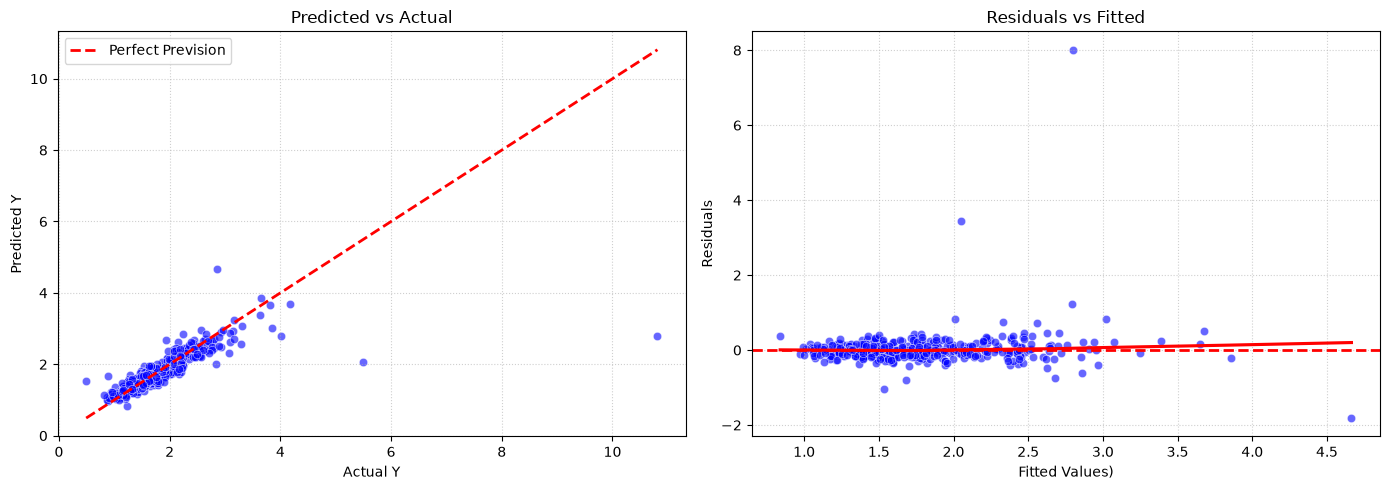

In [11]:
# Gráficos para visualizar a qualidade da regressão linear

residuals = y_test - y_pred_test    # Resíduo = Valor Real - Valor Previsto

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))   # Configurar a área dos gráficos (1 linha, 2 colunas)


# Gráfico1: Valores Previstos vs Valores Reais (Predicted vs Actual)
sns.scatterplot(x=y_test, y=y_pred_test, ax=ax1, alpha=0.6, color='blue')

lims = [np.min([y_test.min(), y_pred_test.min()]), 
        np.max([y_test.max(), y_pred_test.max()])]
ax1.plot(lims, lims, color='red', linestyle='--', lw=2, label='Perfect Prevision')

ax1.set_title('Predicted vs Actual')
ax1.set_xlabel('Actual Y')
ax1.set_ylabel('Predicted Y')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)


# Gráfico2: Resíduos vs Valores Ajustados/Previstos (Residuals vs Fitted)
sns.scatterplot(x=y_pred_test, y=residuals, ax=ax2, alpha=0.6, color='blue')

ax2.axhline(y=0, color='red', linestyle='--', lw=2)  # Linha onde o erro seria nulo

sns.regplot(x=y_pred_test, y=residuals, ax=ax2, scatter=False, color='red', lowess=True) # linha de tendência suave para detetar padrões não-lineares

ax2.set_title('Residuals vs Fitted')
ax2.set_xlabel('Fitted Values)')
ax2.set_ylabel('Residuals')
ax2.grid(True, linestyle=':', alpha=0.6)


plt.tight_layout()
plt.show()

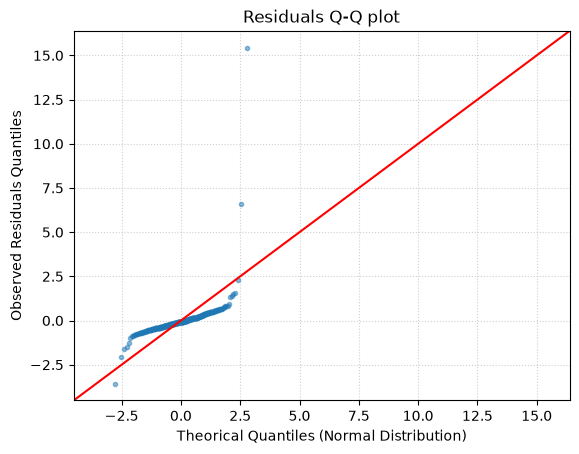

In [12]:
# Gráfico Q-Q
fig = sm.qqplot(residuals, line='45', fit=True) # 'line="45"' adiciona a linha de referência ideal da distribuição normal

fig.gca().lines[0].set_markersize(3)
fig.gca().lines[0].set_alpha(0.5)

plt.title('Residuals Q-Q plot')
plt.xlabel('Theorical Quantiles (Normal Distribution)')
plt.ylabel('Observed Residuals Quantiles')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()